# 01 · Exploration and sanity checks

Issue: [Exploration notebook and sanity checks](../issues/007-exploration-notebook-and-sanity-checks.md).
Purpose: prove on real data that the selection rule and the planned metrics make sense, investigate
the forecast-vs-actual level gap (Q-11), and collect the numbers the method decision
([issue 008](../issues/008-lock-alignment-horizon-and-band-method.md)) needs.

**How to run:** `make notebook` (fresh kernel, top to bottom, outputs and figures saved in place).
**Inputs:** the committed `backend/data/processed/*` files and `notebooks/reference/crosscheck_2026-01-15.json`.
One optional cell also reads the gitignored raw files if they exist (`make data`), and skips cleanly otherwise.

**Conventions:** ✅ = verified by a computation in this notebook · 🔎 = hypothesis, not proven here.
Exploration only: the production metrics live in the Metrics engine ticket; nothing here changes the data or the selection rule.
Error is always `forecast − actual` (ADR 0004), so a positive error means over-forecast.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.figure import Figure

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "backend"))
from app import config  # noqa: E402
from app.selection import parse_cutoff_clock, select_forecasts, target_grid  # noqa: E402

FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
BLUE, ORANGE, GREY = "#1f77b4", "#ff7f0e", "#7f7f7f"


def save(fig: Figure, name: str) -> None:
    """Write a figure to docs/figures with no timestamp metadata, so reruns are byte-stable."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=100, bbox_inches="tight", metadata={"Software": None})


actuals = pd.read_parquet(config.PROCESSED_DIR / "actuals.parquet")
forecasts = pd.read_parquet(config.PROCESSED_DIR / "forecasts.parquet")
quality = json.loads((config.PROCESSED_DIR / "quality_report.json").read_text())
ACTUAL = actuals.set_index("start_time")["generation_mw"]
GRID = target_grid(config.DELIVERY_START, config.DELIVERY_END)
print(f"actuals {actuals.shape}, forecasts {forecasts.shape}, targets {len(GRID)}")

actuals (1536, 4), forecasts (15775, 4), targets 744


In [2]:
POINT, HOUR_MEAN, CENTRED = (0,), (0, 30), (-30, 0)  # half-hour offsets (min) averaged per target


def actual_at(times: pd.Series, offsets: tuple[int, ...] = POINT) -> pd.Series:
    """Mean of the half-hourly actuals that start at each time + offset (minutes)."""
    parts = [(times + pd.Timedelta(minutes=m)).map(ACTUAL) for m in offsets]
    return sum(parts) / len(parts)


def decision(cutoff: str, offsets: tuple[int, ...] = POINT) -> pd.DataFrame:
    """Decision-time forecast per target (app.selection) joined to actuals."""
    out = select_forecasts(forecasts, GRID, parse_cutoff_clock(cutoff))
    out["actual_mw"] = actual_at(out["start_time"], offsets)
    out["error_mw"] = out["forecast_mw"] - out["actual_mw"]
    out["uk_hour"] = out["start_time"].dt.tz_convert(config.TZ).dt.hour
    out["day"] = out["start_time"].dt.tz_convert(config.TZ).dt.date
    return out


def stats(frame: pd.DataFrame, f: str = "forecast_mw", a: str = "actual_mw") -> pd.Series:
    """Exploration-only error summary (MW)."""
    ok = frame[[f, a]].dropna()
    err = ok[f] - ok[a]
    return pd.Series(
        {
            "n": len(ok),
            "mae": err.abs().mean(),
            "rmse": float(np.sqrt((err**2).mean())),
            "bias": err.mean(),
            "p90_abs": err.abs().quantile(0.9),
            "ratio_F/A": ok[f].sum() / ok[a].sum(),
            "r": ok[f].corr(ok[a]),
        }
    )


all_runs = forecasts.assign(actual_mw=forecasts["start_time"].map(ACTUAL))
all_runs["uk_hour"] = all_runs["start_time"].dt.tz_convert(config.TZ).dt.hour
D920, D950 = decision("09:20"), decision("09:50")

## 1 · Coverage, resolution and the publish schedule (PRD §4.4)

In [3]:
runs = forecasts["publish_time"].drop_duplicates()
print(
    "actuals:",
    quality["actuals"]["rows"],
    "of",
    quality["actuals"]["expected"],
    "half-hours;",
    len(quality["actuals"]["missingSlots"]),
    "missing; resolution",
    quality["actuals"]["resolutionMinutes"],
    "min",
)
print(
    "forecasts:",
    len(forecasts),
    "rows in",
    len(runs),
    "runs; resolution",
    quality["forecasts"]["resolutionMinutes"],
    "min; dropped as published after target (E-4):",
    quality["forecasts"]["droppedPublishedAfterTarget"],
)
print("runs per publish day:", runs.dt.date.value_counts().value_counts().to_dict())
print(
    "publish clock (UTC = UK in January):",
    runs.dt.strftime("%H:%M").value_counts().sort_index().to_dict(),
)

actuals: 1536 of 1536 half-hours; 0 missing; resolution 30 min
forecasts: 15775 rows in 272 runs; resolution 60 min; dropped as published after target (E-4): 4081
runs per publish day: {8: 34}
publish clock (UTC = UK in January): {'02:30': 34, '04:30': 34, '07:30': 34, '09:30': 34, '11:30': 33, '12:25': 1, '15:30': 34, '18:30': 34, '22:30': 34}


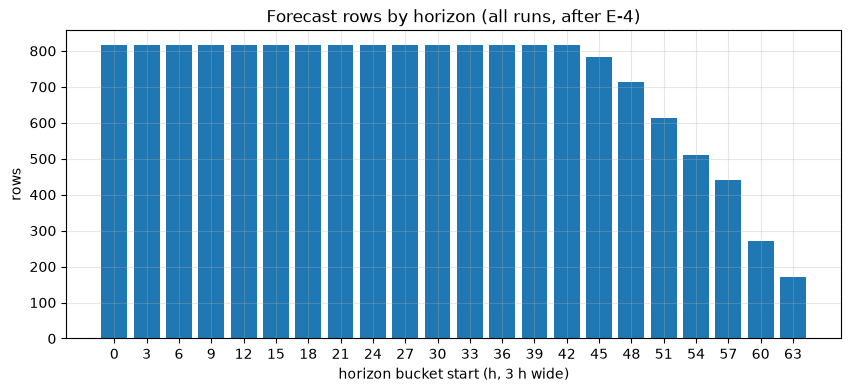

horizon range: 0.5 to 66.5 h


In [4]:
edges = np.arange(0, 69, 3)
counts = pd.cut(forecasts["horizon_h"], edges, right=False).value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar([f"{int(i.left)}" for i in counts.index], counts.to_numpy(), color=BLUE)
ax.set(
    title="Forecast rows by horizon (all runs, after E-4)",
    xlabel="horizon bucket start (h, 3 h wide)",
    ylabel="rows",
)
save(fig, "horizon_distribution")
plt.show()
print("horizon range:", forecasts["horizon_h"].min(), "to", forecasts["horizon_h"].max(), "h")

## 2 · Decision-time selection on real data (`app.selection`)

Each preset should use one run per decision day, never a run published after the cutoff, and leave no target empty.

In [5]:
rows = []
for label, clock in config.CUTOFF_PRESETS.items():
    sel = select_forecasts(forecasts, GRID, parse_cutoff_clock(clock))
    rows.append(
        {
            "preset": label,
            "cutoff": clock,
            "targets": len(sel),
            "missing": int(sel["forecast_mw"].isna().sum()),
            "run clock used": ", ".join(sorted(sel["publish_time"].dt.strftime("%H:%M").unique())),
            "horizon h (min-max)": f"{sel['horizon_h'].min()}-{sel['horizon_h'].max()}",
            "all publish <= cutoff": bool((sel["publish_time"] <= sel["limit_time"]).all()),
        }
    )
pd.DataFrame(rows)

,preset,cutoff,targets,missing,run clock used,horizon h (min-max),all publish <= cutoff
0,EPEX GB,09:20,744,0,07:30,16.5-39.5,True
1,N2EX,09:50,744,0,09:30,14.5-37.5,True
2,Early,06:00,744,0,04:30,19.5-42.5,True


## 3 · One day: runs converge on the actual as the horizon shrinks (PRD §11.4)

Delivery day 15 Jan 2026 (also the cross-check day in §8). Each line is one forecast run.

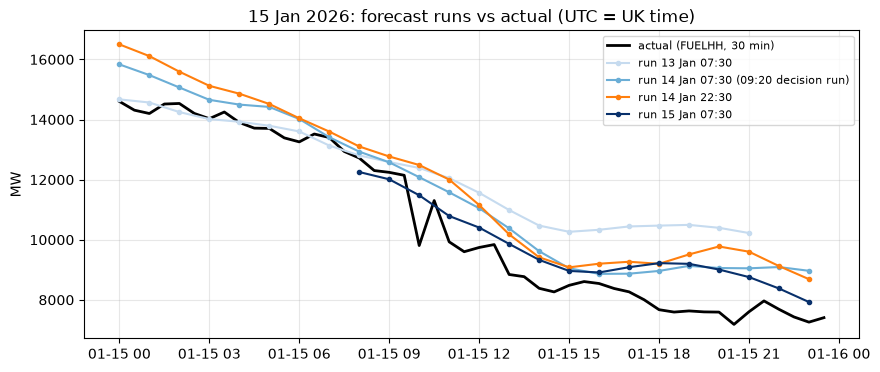

,targets,median_horizon_h,mae
publish_time,,,
2026-01-13 02:30:00+00:00,22.0,56.000,1543.182
2026-01-13 04:30:00+00:00,22.0,54.000,1708.273
2026-01-13 07:30:00+00:00,22.0,51.000,1339.864
2026-01-13 09:30:00+00:00,22.0,49.000,1288.182
2026-01-13 11:30:00+00:00,22.0,47.000,1039.000
2026-01-13 15:30:00+00:00,22.0,43.000,933.136
2026-01-13 18:30:00+00:00,22.0,40.000,1014.545
2026-01-13 22:30:00+00:00,22.0,36.000,1013.227
2026-01-14 02:30:00+00:00,24.0,33.000,1025.250


In [6]:
DAY = pd.Timestamp("2026-01-15", tz=config.TZ)
day_start, day_end = DAY.tz_convert("UTC"), (DAY + pd.Timedelta(days=1)).tz_convert("UTC")
day_runs = all_runs[(all_runs["start_time"] >= day_start) & (all_runs["start_time"] < day_end)]
per_run = (
    day_runs.groupby("publish_time")
    .apply(
        lambda g: pd.Series(
            {
                "targets": len(g),
                "median_horizon_h": g["horizon_h"].median(),
                "mae": (g["generation_mw"] - g["actual_mw"]).abs().mean(),
            }
        ),
        include_groups=False,
    )
    .sort_index()
)
show = [
    pd.Timestamp(t, tz="UTC")
    for t in ("2026-01-13T07:30", "2026-01-14T07:30", "2026-01-14T22:30", "2026-01-15T07:30")
]
fig, ax = plt.subplots()
day_actual = ACTUAL[(ACTUAL.index >= day_start) & (ACTUAL.index < day_end)]
ax.plot(
    day_actual.index, day_actual.to_numpy(), color="black", lw=2, label="actual (FUELHH, 30 min)"
)
for t, colour in zip(show, ("#c6dbef", "#6baed6", ORANGE, "#08306b"), strict=True):
    run = day_runs[day_runs["publish_time"] == t]
    tag = " (09:20 decision run)" if t == show[1] else ""
    ax.plot(
        run["start_time"],
        run["generation_mw"],
        "o-",
        ms=3,
        color=colour,
        label=f"run {t:%d %b %H:%M}{tag}",
    )
ax.set(title="15 Jan 2026: forecast runs vs actual (UTC = UK time)", ylabel="MW")
ax.legend(fontsize=8)
save(fig, "convergence_2026-01-15")
plt.show()
per_run

## 4 · Error by horizon (all runs, PRD §5.5)

Every run, not only the decision run. Long horizons only exist for some hours of the day, because every
run ends at 21:00 UTC on publish day + 2. So the last columns check how much of each bucket is
afternoon/evening (UK 12–21 h), and repeat the analysis for a fixed set of hours.

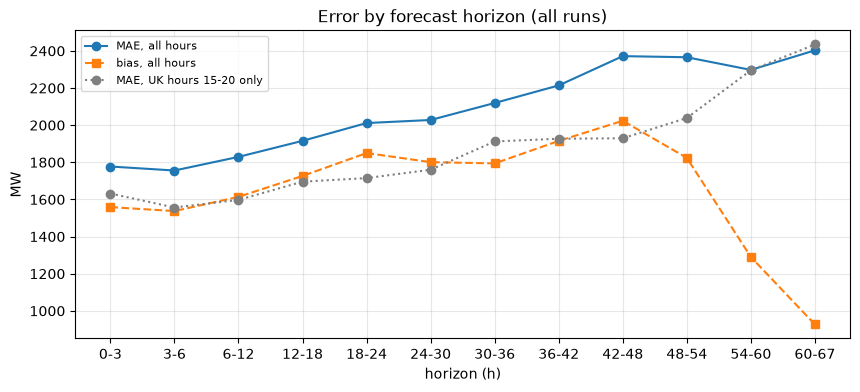

,n,mae,rmse,bias,p90_abs,ratio_F/A,r,share_uk_12_21h,mae_hours_15_20,bias_hours_15_20
bucket,,,,,,,,,,
"[0, 3)",746.0,1777.252,2252.097,1558.574,3684.5,1.135,0.955,0.417,1631.872,1362.872
"[3, 6)",748.0,1755.737,2241.149,1537.221,3786.0,1.133,0.955,0.458,1556.495,1237.312
"[6, 12)",1504.0,1829.102,2296.944,1613.788,3828.0,1.139,0.953,0.499,1597.560,1244.560
"[12, 18)",1518.0,1915.547,2397.289,1726.421,3909.4,1.150,0.951,0.396,1695.649,1266.662
"[18, 24)",1532.0,2011.334,2498.334,1849.690,4034.5,1.163,0.947,0.334,1714.899,1330.552
"[24, 30)",1536.0,2027.792,2499.661,1800.757,4106.0,1.158,0.940,0.438,1759.844,1408.813
"[30, 36)",1536.0,2119.337,2597.299,1793.979,4307.0,1.157,0.925,0.499,1912.255,1445.215
"[36, 42)",1536.0,2213.989,2735.522,1915.122,4394.5,1.167,0.914,0.396,1926.846,1402.341
"[42, 48)",1504.0,2371.721,2920.457,2023.463,4588.8,1.178,0.897,0.341,1929.326,1322.618


In [7]:
H_EDGES = [0, 3, 6, 12, 18, 24, 30, 36, 42, 48, 54, 60, 67]
labelled = all_runs.assign(bucket=pd.cut(all_runs["horizon_h"], H_EDGES, right=False))
by_h = labelled.groupby("bucket", observed=True).apply(
    lambda g: stats(g, "generation_mw"), include_groups=False
)
by_h["share_uk_12_21h"] = labelled.groupby("bucket", observed=True)["uk_hour"].apply(
    lambda h: h.between(12, 21).mean()
)
fixed = labelled[labelled["uk_hour"].between(15, 20)]
by_h["mae_hours_15_20"] = fixed.groupby("bucket", observed=True).apply(
    lambda g: stats(g, "generation_mw")["mae"], include_groups=False
)
by_h["bias_hours_15_20"] = fixed.groupby("bucket", observed=True).apply(
    lambda g: stats(g, "generation_mw")["bias"], include_groups=False
)
fig, ax = plt.subplots()
x = [f"{int(i.left)}-{int(i.right)}" for i in by_h.index]
ax.plot(x, by_h["mae"], "o-", color=BLUE, label="MAE, all hours")
ax.plot(x, by_h["bias"], "s--", color=ORANGE, label="bias, all hours")
ax.plot(x, by_h["mae_hours_15_20"], "o:", color=GREY, label="MAE, UK hours 15-20 only")
ax.set(title="Error by forecast horizon (all runs)", xlabel="horizon (h)", ylabel="MW")
ax.legend(fontsize=8)
save(fig, "error_by_horizon")
plt.show()
by_h

In [8]:
prd_bins = [0, 6, 12, 24, 36, 48, np.inf]
print("PRD horizon bins (FR-2.7 / §5.5), rows per bin:")
print(pd.cut(forecasts["horizon_h"], prd_bins, right=False).value_counts().sort_index().to_string())

PRD horizon bins (FR-2.7 / §5.5), rows per bin:
horizon_h
[0.0, 6.0)      1632
[6.0, 12.0)     1632
[12.0, 24.0)    3264
[24.0, 36.0)    3264
[36.0, 48.0)    3230
[48.0, inf)     2753


## 5 · Alignment: forecast timestamp vs hour-mean of actuals (ADR 0003, Q-2)

WINDFOR is hourly; FUELHH is half-hourly averages. Three ways to pick the comparison actual for a forecast at t:
**point** = the half-hour starting at t (PRD default); **hour-mean** = mean of the half-hours starting at t and t+30;
**centred** = mean of the half-hours starting at t−30 and t. A lag scan on the 0–3 h runs (least weather-timing
error) tests which convention the forecast timestamps follow.

In [9]:
align = pd.DataFrame(
    {
        f"{cut} {name}": stats(decision(cut, offs))
        for cut in ("09:20", "09:50")
        for name, offs in (("point", POINT), ("hour-mean", HOUR_MEAN), ("centred", CENTRED))
    }
).T
align

,n,mae,rmse,bias,p90_abs,ratio_F/A,r
09:20 point,744.0,2022.470,2497.407,1745.938,4154.40,1.155,0.932
09:20 hour-mean,744.0,2038.913,2504.759,1747.887,4097.90,1.155,0.931
09:20 centred,744.0,2003.821,2486.836,1741.008,4126.00,1.154,0.933
09:50 point,744.0,1995.569,2498.825,1727.983,4183.90,1.153,0.932
09:50 hour-mean,744.0,2013.008,2505.943,1729.931,4143.85,1.153,0.931
09:50 centred,744.0,1975.012,2488.246,1723.052,4196.35,1.153,0.933


In [10]:
short = all_runs[all_runs["horizon_h"] < 3]
lags = []
for lag_h in (-1.5, -1.0, -0.5, 0.0, 0.5, 1.0):
    act = (short["start_time"] + pd.Timedelta(hours=lag_h)).map(ACTUAL)
    ok = act.notna()
    lags.append(
        {
            "actual shifted by (h)": lag_h,
            "n": int(ok.sum()),
            "r": short.loc[ok, "generation_mw"].corr(act[ok]),
            "mae": (short.loc[ok, "generation_mw"] - act[ok]).abs().mean(),
        }
    )
pd.DataFrame(lags)

,actual shifted by (h),n,r,mae
0,-1.5,744,0.952,1768.372
1,-1.0,745,0.955,1753.264
2,-0.5,745,0.957,1750.585
3,0.0,746,0.955,1777.252
4,0.5,746,0.953,1791.637
5,1.0,747,0.948,1830.256


## 6 · Signed-error quantiles at the cutoff (ADR 0006, Q-3, Q-5)

Point alignment. A band `[F − q_hi, F − q_lo]` contains F only if `q_lo ≤ 0 ≤ q_hi` (Q-3). Calibration window (Q-5):
quantiles per delivery week show how stable a whole-month calibration is, and a leave-one-week-out check shows
out-of-sample coverage.

In [11]:
def quantiles(frame: pd.DataFrame) -> pd.Series:
    e = frame["error_mw"].dropna()
    q = e.quantile([0.05, 0.10, 0.50, 0.90, 0.95])
    return pd.Series(
        {
            "q05": q[0.05],
            "q10": q[0.10],
            "q50": q[0.50],
            "q90": q[0.90],
            "q95": q[0.95],
            "80% band contains F": bool(q[0.10] <= 0 <= q[0.90]),
            "90% band contains F": bool(q[0.05] <= 0 <= q[0.95]),
            "80% width": q[0.90] - q[0.10],
            "90% width": q[0.95] - q[0.05],
        }
    )


pd.DataFrame({"09:20": quantiles(D920), "09:50": quantiles(D950)}).T

,q05,q10,q50,q90,q95,80% band contains F,90% band contains F,80% width,90% width
09:20,-1038.65,-426.4,1581.5,4154.4,5268.35,True,True,4580.8,6307.0
09:50,-1041.4,-502.7,1506.5,4183.9,5319.0,True,True,4686.6,6360.4


In [12]:
weeks = D920.assign(week=pd.to_datetime(D920["day"]).dt.isocalendar().week.astype(int))
per_week = weeks.groupby("week").apply(
    lambda g: pd.Series(
        {
            "days": g["day"].nunique(),
            "n": g["error_mw"].notna().sum(),
            "q10": g["error_mw"].quantile(0.1),
            "q90": g["error_mw"].quantile(0.9),
            "bias": g["error_mw"].mean(),
        }
    ),
    include_groups=False,
)
lowo = []
for week, held in weeks.groupby("week"):
    rest = weeks.loc[weeks["week"] != week, "error_mw"]
    lo, hi = rest.quantile(0.1), rest.quantile(0.9)
    lowo.append(
        {
            "week": week,
            "held_n": int(held["error_mw"].notna().sum()),
            "coverage of 80% band": held["error_mw"].between(lo, hi).mean(),
        }
    )
lowo = pd.DataFrame(lowo).set_index("week")
in_sample = (
    D920["error_mw"].between(D920["error_mw"].quantile(0.1), D920["error_mw"].quantile(0.9)).mean()
)
pooled = (lowo["coverage of 80% band"] * lowo["held_n"]).sum() / lowo["held_n"].sum()
print(f"in-sample 80% coverage: {in_sample:.3f}; leave-one-week-out pooled coverage: {pooled:.3f}")
per_hour = D920.groupby("uk_hour")["error_mw"].quantile([0.1, 0.9]).unstack()
print(
    f"per-hour q10 range {per_hour[0.1].min():.0f}..{per_hour[0.1].max():.0f} MW, "
    f"q90 range {per_hour[0.9].min():.0f}..{per_hour[0.9].max():.0f} MW"
)
per_week.join(lowo, how="left")

in-sample 80% coverage: 0.798; leave-one-week-out pooled coverage: 0.784
per-hour q10 range -1445..596 MW, q90 range 3116..5050 MW


,days,n,q10,q90,bias,held_n,coverage of 80% band
week,,,,,,,
1,3.0,72.0,659.1,3839.3,2090.472,72,0.958
2,7.0,168.0,-1292.8,4242.7,1376.393,168,0.714
3,7.0,168.0,-1003.5,3704.4,1371.875,168,0.732
4,7.0,168.0,-686.5,3551.2,1619.726,168,0.780
5,7.0,168.0,725.6,5163.5,2468.101,168,0.833


## 7 · Q-11: the forecast-vs-actual level gap

Questions: does the gap shrink with horizon (forecast skill) or persist (definition/scope)? Is it proportional
(same ratio at all wind levels) or concentrated at high wind / low demand, which is the pattern curtailment would leave?
Grouping by the **actual** level is biased by regression to the mean (a low actual is partly a forecast miss), so the
**forecast** level is the fairer grouping; both are shown.

In [13]:
bands = [-np.inf, 5000, 10000, 15000, np.inf]
names = ["<5 GW", "5-10 GW", "10-15 GW", ">15 GW"]
level = pd.DataFrame(
    {
        "by forecast level": D920.groupby(
            pd.cut(D920["forecast_mw"], bands, labels=names), observed=True
        )
        .apply(lambda g: stats(g)[["n", "bias", "ratio_F/A"]], include_groups=False)
        .stack(),
        "by actual level (biased)": D920.groupby(
            pd.cut(D920["actual_mw"], bands, labels=names), observed=True
        )
        .apply(lambda g: stats(g)[["n", "bias", "ratio_F/A"]], include_groups=False)
        .stack(),
    }
).unstack()
slope, intercept = np.polyfit(D920["actual_mw"], D920["forecast_mw"], 1)
print(f"OLS at 09:20: forecast = {intercept:.0f} MW + {slope:.3f} x actual")
level

OLS at 09:20: forecast = 931 MW + 1.072 x actual


by forecast level                     by actual level (biased)                    
                         n      bias ratio_F/A                        n      bias ratio_F/A
<5 GW                 31.0   578.839     1.154                     61.0  2229.607     1.599
5-10 GW              214.0   772.061     1.109                    247.0  1202.000     1.155
10-15 GW             201.0  1574.005     1.146                    242.0  1842.583     1.143
>15 GW               298.0  2682.678     1.174                    194.0  2165.840     1.134

gap vs daily mean actual: corr 0.34
5 windiest days: gap 2189 MW, ratio 1.135; 5 calmest: gap 2082 MW, ratio 1.376
UK 00-06h: bias 2210 MW, ratio 1.199; 12-18h: bias 1350 MW, ratio 1.119


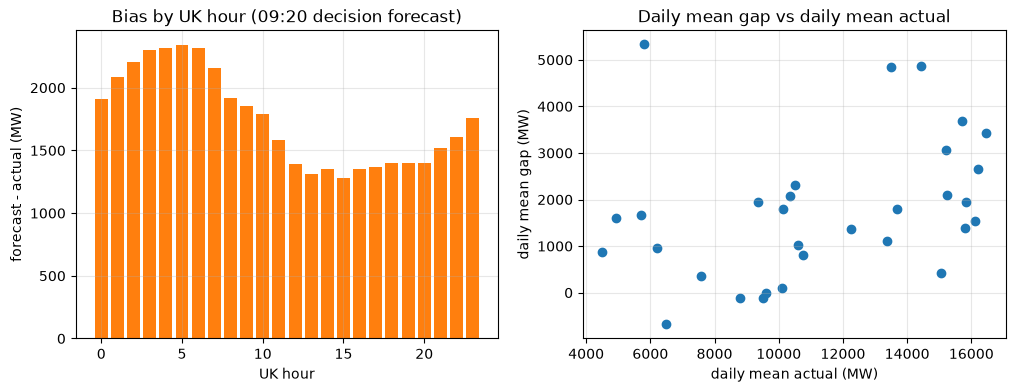

In [14]:
by_hour = D920.groupby("uk_hour").apply(
    lambda g: stats(g)[["bias", "ratio_F/A"]], include_groups=False
)
daily = D920.groupby("day").agg(forecast=("forecast_mw", "mean"), actual=("actual_mw", "mean"))
daily["gap"] = daily["forecast"] - daily["actual"]
daily["ratio"] = daily["forecast"] / daily["actual"]
windy, calm = daily.nlargest(5, "actual"), daily.nsmallest(5, "actual")
night = D920[D920["uk_hour"].between(0, 6)]
afternoon = D920[D920["uk_hour"].between(12, 18)]
print(f"gap vs daily mean actual: corr {daily['gap'].corr(daily['actual']):.2f}")
print(
    f"5 windiest days: gap {windy['gap'].mean():.0f} MW, ratio {windy['ratio'].mean():.3f}; "
    f"5 calmest: gap {calm['gap'].mean():.0f} MW, ratio {calm['ratio'].mean():.3f}"
)
print(
    f"UK 00-06h: bias {stats(night)['bias']:.0f} MW, ratio {stats(night)['ratio_F/A']:.3f}; "
    f"12-18h: bias {stats(afternoon)['bias']:.0f} MW, ratio {stats(afternoon)['ratio_F/A']:.3f}"
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(by_hour.index, by_hour["bias"], color=ORANGE)
ax1.set(
    title="Bias by UK hour (09:20 decision forecast)",
    xlabel="UK hour",
    ylabel="forecast - actual (MW)",
)
ax2.scatter(daily["actual"], daily["gap"], color=BLUE)
ax2.set(
    title="Daily mean gap vs daily mean actual",
    xlabel="daily mean actual (MW)",
    ylabel="daily mean gap (MW)",
)
save(fig, "q11_level_gap")
plt.show()

In [15]:
# Optional: hindcast rows (publish_time > start_time) exist only in the gitignored raw files;
# the dataset build drops them (E-4).
raw_files = sorted(config.RAW_DIR.glob("windfor_*.json"))
if not raw_files:
    print("skipped: raw files not present (run `make data` to include this check)")
else:
    raw = pd.DataFrame([r for p in raw_files for r in json.loads(p.read_text())])
    raw["start_time"] = pd.to_datetime(raw["startTime"], utc=True)
    raw["horizon_h"] = (
        raw["start_time"] - pd.to_datetime(raw["publishTime"], utc=True)
    ) / pd.Timedelta(hours=1)
    past = (
        raw[raw["horizon_h"] < 0].assign(actual_mw=lambda d: d["start_time"].map(ACTUAL)).dropna()
    )
    frozen = past.groupby("start_time")["generation"].nunique().eq(1).mean()
    last_pre = forecasts.sort_values("publish_time").groupby("start_time")["generation_mw"].last()
    frozen_value = past.groupby("start_time")["generation"].first()
    same_as_last = frozen_value.eq(last_pre.reindex(frozen_value.index)).mean()
    gap_to_last = (frozen_value - last_pre.reindex(frozen_value.index)).abs().median()
    hc_mae = (past["generation"] - past["actual_mw"]).abs().mean()
    hc_ratio = past["generation"].sum() / past["actual_mw"].sum()
    print(
        f"hindcast rows {len(past)}: ratio F/A {hc_ratio:.3f}, "
        f"MAE vs metered {hc_mae:.0f} MW (0-3 h forecasts: {by_h['mae'].iloc[0]:.0f} MW)"
    )
    print(
        f"value identical across all later runs for {frozen:.0%} of targets; equal to the last "
        f"pre-start forecast for {same_as_last:.0%} (median |difference| {gap_to_last:.0f} MW)"
    )

hindcast rows 3697: ratio F/A 1.152, MAE vs metered 1884 MW (0-3 h forecasts: 1777 MW)
value identical across all later runs for 100% of targets; equal to the last pre-start forecast for 9% (median |difference| 151 MW)


## 8 · Cross-check of one day against the BMRS source endpoints

The BMRS website charts are rendered client-side from the same Insights API, so instead of a screenshot this
compares our processed values with two **independent** endpoints, saved in `reference/crosscheck_2026-01-15.json`
(fetched 2026-10-25): the forecast-history endpoint behind the BMRS wind forecast page, and the 5-minute FUELINST
wind outturn behind the generation-by-fuel-type page, averaged to half-hours.

In [16]:
ref = json.loads((Path("reference") / "crosscheck_2026-01-15.json").read_text())
hist = pd.DataFrame(ref["windforecast_history"]["rows"])
hist["start_time"] = pd.to_datetime(hist["startTime"], utc=True)
run = forecasts[forecasts["publish_time"] == pd.Timestamp("2026-01-14T07:30Z")]
both = run.merge(hist, on="start_time")
print(
    f"forecast run 14 Jan 07:30: {len(both)} of {len(run)} processed values matched; "
    f"max |difference| = {(both['generation_mw'] - both['generation']).abs().max():.1f} MW"
)

inst = pd.DataFrame(ref["fuelinst_wind"]["rows"])
inst["half_hour"] = pd.to_datetime(inst["startTime"], utc=True).dt.floor("30min")
inst_hh = inst.groupby("half_hour")["generation"].mean()
cmp = pd.DataFrame({"fuelhh": ACTUAL, "fuelinst_mean": inst_hh}).dropna()
diff = cmp["fuelhh"] - cmp["fuelinst_mean"]
print(
    f"actuals 15 Jan: {len(cmp)} half-hours; FUELHH - mean(FUELINST): mean {diff.mean():.1f} MW, "
    f"max |diff| {diff.abs().max():.1f} MW, daily mean {cmp['fuelhh'].mean():.0f} vs "
    f"{cmp['fuelinst_mean'].mean():.0f} MW"
)

forecast run 14 Jan 07:30: 62 of 62 processed values matched; max |difference| = 0.0 MW
actuals 15 Jan: 48 half-hours; FUELHH - mean(FUELINST): mean -0.6 MW, max |diff| 90.7 MW, daily mean 10568 vs 10568 MW


## 9 · KPI maths for the Decision view (Q-2)

FR-3.2 asks for daily forecast energy (MWh); FR-3.4 for "actual inside the band N of M". With hourly forecasts:
forecast energy = Σ forecast × 1 h; actual energy = Σ half-hourly actual × 0.5 h; the band is evaluated at the
24 hourly points.

In [17]:
q10, q90 = D920["error_mw"].quantile(0.1), D920["error_mw"].quantile(0.9)
day = D920[D920["day"] == DAY.date()]
lower, upper = (day["forecast_mw"] - q90).clip(lower=0), (day["forecast_mw"] - q10).clip(lower=0)
inside = day["actual_mw"].between(lower, upper)
energy_f = day["forecast_mw"].sum() * 1.0
energy_a = day_actual.sum() * 0.5
print(
    f"15 Jan at 09:20: {len(day)} evaluation points; "
    f"actual inside the 80% band at {inside.sum()} of {len(day)}"
)
print(
    f"energy: forecast {energy_f:,.0f} MWh vs actual {energy_a:,.0f} MWh "
    f"({energy_f / energy_a - 1:+.1%})"
)

15 Jan at 09:20: 24 evaluation points; actual inside the 80% band at 24 of 24
energy: forecast 278,630 MWh vs actual 253,626 MWh (+9.9%)


## 10 · Findings for the method decision

The numbers below are recomputed on every run; the interpretation that follows was written from this run.

In [18]:
o = stats(D920)
lag_table = pd.DataFrame(lags)
best_lag = lag_table.loc[lag_table["r"].idxmax(), "actual shifted by (h)"]
q05, q95 = D920["error_mw"].quantile(0.05), D920["error_mw"].quantile(0.95)
h_min, h_max = forecasts["horizon_h"].min(), forecasts["horizon_h"].max()
long_rows = int((forecasts["horizon_h"] >= 48).sum())
mae_of = {k: f"{align.loc[f'09:20 {k}', 'mae']:.0f}" for k in ("point", "hour-mean", "centred")}
ratio_h = by_h["ratio_F/A"]
findings = {
    "coverage": f"{len(GRID)} targets, 0 missing at every preset; "
    f"actuals {quality['actuals']['rows']}/1536",
    "headline 09:20 (point)": f"MAE {o['mae']:.0f}, RMSE {o['rmse']:.0f}, "
    f"bias {o['bias']:+.0f} MW, ratio {o['ratio_F/A']:.3f}, r {o['r']:.3f}",
    "Q-2 alignment MAE 09:20 point / hour-mean / centred": " / ".join(mae_of.values()),
    "Q-2 lag scan best r (0-3 h runs)": f"actual shifted {best_lag:+.1f} h",
    "Q-2 15 Jan inside 80% band": f"{inside.sum()}/{len(day)} hourly points",
    "Q-3 q10..q90 / q05..q95 at 09:20": f"{q10:.0f}..{q90:.0f} / {q05:.0f}..{q95:.0f} MW "
    f"(contain 0: {q10 <= 0 <= q90})",
    "Q-4 horizon range / rows >48 h": f"{h_min}-{h_max} h / {long_rows}",
    "Q-4 MAE 0-3 h vs 42-48 h": f"{by_h['mae'].iloc[0]:.0f} vs {by_h['mae'].iloc[8]:.0f} MW",
    "Q-5 80% coverage in-sample / leave-one-week-out": f"{in_sample:.3f} / {pooled:.3f}",
    "Q-11 ratio 0-3 h / decision / 42-48 h": f"{ratio_h.iloc[0]:.3f} / {o['ratio_F/A']:.3f} / "
    f"{ratio_h.iloc[8]:.3f}",
    "Q-11 OLS": f"forecast = {intercept:.0f} + {slope:.3f} x actual",
    "Q-11 night (00-06) vs afternoon (12-18) bias": f"{stats(night)['bias']:.0f} vs "
    f"{stats(afternoon)['bias']:.0f} MW",
    "cross-check": f"forecast run exact match {len(both)} values; "
    f"FUELHH vs FUELINST mean diff {diff.mean():.1f} MW",
}
for key, value in findings.items():
    print(f"{key:55s} {value}")

coverage                                                744 targets, 0 missing at every preset; actuals 1536/1536
headline 09:20 (point)                                  MAE 2022, RMSE 2497, bias +1746 MW, ratio 1.155, r 0.932
Q-2 alignment MAE 09:20 point / hour-mean / centred     2022 / 2039 / 2004
Q-2 lag scan best r (0-3 h runs)                        actual shifted -0.5 h
Q-2 15 Jan inside 80% band                              24/24 hourly points
Q-3 q10..q90 / q05..q95 at 09:20                        -426..4154 / -1039..5268 MW (contain 0: True)
Q-4 horizon range / rows >48 h                          0.5-66.5 h / 2753
Q-4 MAE 0-3 h vs 42-48 h                                1777 vs 2372 MW
Q-5 80% coverage in-sample / leave-one-week-out         0.798 / 0.784
Q-11 ratio 0-3 h / decision / 42-48 h                   1.135 / 1.155 / 1.178
Q-11 OLS                                                forecast = 931 + 1.072 x actual
Q-11 night (00-06) vs afternoon (12-18) bias            2210

### Interpretation (✅ verified here · 🔎 hypothesis)

**Verified on this data (✅)**

1. **Selection and coverage:** all 744 targets have a decision-time forecast at every preset, and nothing was published after its cutoff. 09:20 uses the 07:30 run on D-1 (16.5–39.5 h ahead); 09:50 uses the 09:30 run (14.5–37.5 h).
2. **Cross-check (§8):** the 14 Jan 07:30 run matches the BMRS forecast-history endpoint exactly (62/62 values, 0.0 MW). FUELHH matches the half-hour mean of 5-minute FUELINST to −0.6 MW on average (max 91 MW) on 15 Jan.
3. **Error grows with horizon:** MAE is 1,777 MW at 0–3 h and 2,372 MW at 42–48 h; correlation falls from 0.955 to 0.897.
4. **Alignment barely matters:** at 09:20 the MAE is 2,022 (point), 2,039 (hour-mean) and 2,004 MW (centred), and the bias is about +1,745 MW in all three.
5. **Error quantiles at 09:20:** q10 −426, q90 +4,154, q05 −1,039, q95 +5,268 MW. Both bands contain the forecast, but the margin on the low side is small, and the band sits mostly **below** the forecast.
6. **Calibration is not stable week to week:** q10 ranges from −1,293 to +726 MW by delivery week. Leave-one-week-out coverage of the 80 % band is 0.71–0.96 by week (pooled 0.784, against 0.798 in-sample).
7. **The level gap persists at short horizons:** forecast ÷ actual is 1.135 at 0–3 h, 1.155 for the decision forecast and 1.178 at 42–48 h. Values for hours already past (hindcasts, raw only) are frozen across later runs, still 1.152× actual, and no closer to metered output (MAE 1,884 MW). They are not outturn.
8. **Shape of the gap:**
   - By forecast level the ratio is 1.11–1.17. The bias is +579 MW below 5 GW and +2,683 MW above 15 GW, and the OLS fit is forecast = 931 + 1.072 × actual.
   - The gap is larger at night: UK 00–06 h bias is +2,210 MW (ratio 1.199), against +1,350 MW (1.119) at 12–18 h.
   - The daily gap is only weakly related to daily wind (r = 0.34).
9. **KPI maths:** there are 24 evaluation points per day. On 15 Jan, forecast energy was 278,630 MWh against 253,626 MWh actual (+9.9 %), and the actual stayed inside the 80 % band at 24 of 24 points (in-sample).

**Hypotheses, not proven here (🔎)**

- **Q-11 cause:** the evidence is mixed and cannot be settled with only FUELHH and WINDFOR, which the brief restricts us to. No Elexon or NESO document found states the convention.
  - *Fits a definitional difference such as unconstrained forecast vs curtailed metered output:* the gap does not shrink as the horizon goes to 0; it is larger at night, when low demand makes constraint actions more likely; and it is larger in MW at high wind.
  - *Fits a proportional scale difference such as fleet or capacity definition:* the gap is already present below 5 GW (+579 MW, ratio 1.15), and the OLS intercept is positive.
- **Q-13 timestamp convention:** on the 0–3 h runs, correlation peaks when the actual is shifted 0.5 h earlier (r 0.957 vs 0.955), and the centred alignment has the lowest MAE. A WINDFOR value may therefore be a point or centred value at t rather than the mean of the hour that starts at t. The effect is below 1 % of MAE.
- **Q-14 long horizons:** the bias falls beyond 48 h (+926 MW at 60–67 h) while the MAE keeps rising. Part of this is composition, since only UK afternoon and evening hours exist there, but it also shows within fixed UK hours 15–20 (+1,363 → +943 MW). Long-range forecasts may simply be smoother. This does not touch the decision forecast, which is 16.5–39.5 h ahead.

**What the method decision (issue 008) has to settle, with these numbers**

- **(a) Alignment:** point (PRD default), hour-mean or centred. They differ by under 2 % in MAE, and the bias is identical.
- **(b) Horizon bins:** every PRD bin is populated (1,632 rows in 0–6 h). Data runs to 66.5 h (2,753 rows ≥ 48 h), but those rows cover only some hours of the day. `by=horizon` should ignore `cutoff`.
- **(c) Band calibration:** whole month (in-sample 0.798, out-of-sample about 0.784) or a narrower window, which is unstable week to week. Per-hour quantiles would vary the band (q10 −1,445…+596, q90 3,116…5,050 MW across UK hours).
- **(d) FR-3.4 wording:** "N of 24 hourly points". FR-3.2 energy uses forecast × 1 h and actual × 0.5 h.
- **(e) Test 11.2.5:** it holds on this data, but only just (q10 = −426 MW). `0 ≤ lower ≤ upper` is still the safer test.
- **(f) Presenting the level gap:** the band is built from *signed* errors, so it is centred near forecast − 1.58 GW and already absorbs the gap whatever its cause. The open choice is how to word the +1.75 GW (≈ 15 %) bias and its unknown cause for the client.

**Limitations:** one month, in-sample unless stated; the cross-check is numeric (API) rather than a screenshot; the hindcast check needs the gitignored raw files; the root-cause analysis is limited to the two datasets in the brief.